# TACO Trash Detection — YOLO11s

## Cell 1 — Install packages

In [1]:
%pip -q install "ultralytics>=8.3.0" "iterative-stratification>=0.1.9" pandas pyyaml requests tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 76.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 10.7 MB/s eta 0:00:00


## Cell 2 — Import, Drive mount, and all configuration

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from io import BytesIO
import hashlib
import json
import os
import random
import shutil
import time
import zipfile

import numpy as np
import pandas as pd
import requests
import torch
import yaml
from PIL import Image
from tqdm.auto import tqdm
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Isolated 8-class paths: do not reuse older 8-class or 9-class datasets and checkpoints.
DRIVE_ROOT = Path('/content/drive/MyDrive/TACO_Custom8_CVLight_YOLO11s')
DATASET_ROOT = Path('/content/taco_custom8_cvlight')
RAW_ROOT = Path('/content/taco_custom8_raw')
COCO_JSON = RAW_ROOT / 'annotations.json'
DATA_CACHE_ZIP = DRIVE_ROOT / 'taco_custom8_split80_10_10_seed42.zip'
RUNS_DIR = DRIVE_ROOT / 'runs'
EVAL_DIR = DRIVE_ROOT / 'evaluation'
EXPORT_DIR = DRIVE_ROOT / 'model_for_teammates'
ANNOTATIONS_URL = 'https://raw.githubusercontent.com/pedropro/TACO/master/data/annotations.json'

CLASS_NAMES = [
    'Plastic Bag & Wrapper',
    'Cigarette',
    'Bottle',
    'Bottle Cap & Lid',
    'Can',
    'Cup',
    'Paper & Cardboard',
    'Other Litter',
]
CLASS_INDEX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.80, 0.10, 0.10
REBUILD_DATASET = False  # True deliberately discards this experiment's cached dataset.

MODEL_NAME = 'yolo11s.pt'
EPOCHS = 120
PATIENCE = 20
IMAGE_SIZE = 896
BATCH_SIZE = 16
MOSAIC = 0.5
# Use the CPU cores actually available to this Colab process (usually 2-4).
AVAILABLE_CPUS = (
    len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity')
    else (os.cpu_count() or 2)
)
WORKERS = min(4, max(1, AVAILABLE_CPUS))

for folder in [DRIVE_ROOT, RAW_ROOT, RUNS_DIR, EVAL_DIR, EXPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print('Available CPU cores:', AVAILABLE_CPUS)
print('Configured dataloader workers:', WORKERS)
print('Configured number of classes:', len(CLASS_NAMES))
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('GPU memory (GiB):', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
else:
    print('No CUDA GPU detected. Enable GPU before the training cell.')


Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Available CPU cores: 12
Configured dataloader workers: 4
Configured number of classes: 8
GPU: NVIDIA A100-SXM4-40GB
GPU memory (GiB): 39.49


## Cell 3 — Download official annotations and source images


In [3]:
def read_coco_annotations():
    if not COCO_JSON.is_file():
        response = requests.get(ANNOTATIONS_URL, timeout=90)
        response.raise_for_status()
        COCO_JSON.write_bytes(response.content)
    coco = json.loads(COCO_JSON.read_text(encoding='utf-8'))
    if not all(k in coco for k in ('images', 'annotations', 'categories')):
        raise ValueError('Invalid TACO COCO file.')
    return coco


def download_taco_image(image_record):
    image_id = int(image_record['id'])
    target = RAW_ROOT / f'{image_id:06d}.jpg'
    expected_width = int(image_record['width'])
    expected_height = int(image_record['height'])

    def is_compatible(img):
        if img.width < 32 or img.height < 32 or expected_width <= 0 or expected_height <= 0:
            return False
        original_ratio = expected_width / expected_height
        return abs(img.width / img.height - original_ratio) / original_ratio < 0.015

    if target.exists():
        try:
            with Image.open(target) as cached:
                cached.load()
                if is_compatible(cached):
                    return image_id, target, 'cached'
        except Exception:
            pass
        target.unlink(missing_ok=True)

    urls = [image_record.get('flickr_url'), image_record.get('flickr_640_url')]
    for url_number, url in enumerate(urls):
        if not url:
            continue
        for attempt in range(2):
            try:
                response = requests.get(url, timeout=30, headers={'User-Agent': 'Mozilla/5.0'})
                response.raise_for_status()
                with Image.open(BytesIO(response.content)) as pil_image:
                    img = pil_image.convert('RGB')
                if not is_compatible(img):
                    continue
                temp = target.with_suffix('.part')
                img.save(temp, format='JPEG', quality=94)
                temp.replace(target)
                return image_id, target, ('original' if url_number == 0 else 'fallback_640')
            except (requests.RequestException, ValueError, OSError):
                continue
    return image_id, None, 'unavailable'


def collect_source_images(coco):
    found = {}
    with ThreadPoolExecutor(max_workers=8) as executor:
        futures = [executor.submit(download_taco_image, record) for record in coco['images']]
        for future in tqdm(as_completed(futures), total=len(futures), desc='Source images'):
            img_id, path, status = future.result()
            found[img_id] = {'path': str(path) if path else None, 'status': status}
    print('Download status:', dict(Counter(info['status'] for info in found.values())))
    usable = sum(info['path'] is not None for info in found.values())
    print('Usable images:', usable, '/', len(coco['images']))
    if usable < 100:
        raise RuntimeError('Too few TACO images were downloaded. Check network / Flickr URLs.')
    return found

## Cell 4 — Convert the original 60 TACO categories into 8 classes

In [4]:
def yolo_xywh_from_coco(box, width, height):
    x, y, w, h = map(float, box)
    left = min(max(x, 0.0), float(width))
    top = min(max(y, 0.0), float(height))
    right = min(max(x + w, 0.0), float(width))
    bottom = min(max(y + h, 0.0), float(height))
    if right <= left or bottom <= top:
        return None
    return ((left + right) / (2 * width),
            (top + bottom) / (2 * height),
            (right - left) / width,
            (bottom - top) / height)


def map_taco_category(category):
    """Map one *original* COCO category into our agreed 8-class ontology."""
    name = str(category.get('name', '')).strip().casefold()
    supercategory = str(category.get('supercategory', '')).strip().casefold()

    # Explicit category-based mapping for cross-supercategory merges.
    if name in {'plastic lid', 'metal lid', 'plastic bottle cap', 'metal bottle cap'}:
        return CLASS_INDEX['Bottle Cap & Lid']
    if name in {'disposable plastic cup', 'paper cup', 'foam cup',
                'glass cup', 'other plastic cup'}:
        return CLASS_INDEX['Cup']
    if name in {'normal paper', 'magazine paper', 'wrapping paper', 'tissues',
                'paper bag', 'plastified paper bag', 'toilet tube'}:
        return CLASS_INDEX['Paper & Cardboard']
    if name in {'crisp packet', 'plastic film', 'other plastic wrapper',
                'single-use carrier bag', 'garbage bag', 'polypropylene bag'}:
        return CLASS_INDEX['Plastic Bag & Wrapper']

    # General mapping by the official TACO supercategory.
    superclass_to_target = {
        'plastic bag & wrapper': 'Plastic Bag & Wrapper',
        'cigarette': 'Cigarette',
        'bottle': 'Bottle',
        'bottle cap': 'Bottle Cap & Lid',
        'lid': 'Bottle Cap & Lid',
        'can': 'Can',
        'cup': 'Cup',
        'carton': 'Paper & Cardboard',
        'paper': 'Paper & Cardboard',
        'paper bag': 'Paper & Cardboard',
    }
    return CLASS_INDEX[superclass_to_target.get(supercategory, 'Other Litter')]


def make_examples(coco, downloaded):
    categories = {int(cat['id']): cat for cat in coco['categories']}
    original_to_target = {cat_id: map_taco_category(cat)
                          for cat_id, cat in categories.items()}
    assert len(original_to_target) == len(categories)
    assert set(original_to_target.values()) == set(range(len(CLASS_NAMES))), (
        'Class mapping has an unused target class. Check the TACO categories.'
    )

    annotation_counts = Counter(int(ann['category_id']) for ann in coco['annotations'])
    category_report = []
    for category_id, cat in sorted(categories.items()):
        target_id = original_to_target[category_id]
        category_report.append({
            'original_category_id': category_id,
            'original_category': cat['name'],
            'original_supercategory': cat.get('supercategory', ''),
            'new_class_id': target_id,
            'new_class': CLASS_NAMES[target_id],
            'annotation_count': annotation_counts[category_id],
        })
    pd.DataFrame(category_report).to_csv(DRIVE_ROOT / 'category_mapping.csv', index=False)
    print('Mapping saved to:', DRIVE_ROOT / 'category_mapping.csv')
    print(pd.DataFrame(category_report).groupby('new_class')['annotation_count'].sum())

    annotations = defaultdict(list)
    for ann in coco['annotations']:
        original_id = int(ann['category_id'])
        if original_id not in original_to_target:
            raise ValueError(f'Unknown original category ID: {original_id}')
        annotations[int(ann['image_id'])].append((original_to_target[original_id], ann['bbox']))

    examples = []
    seen_checksums = set()
    duplicate_count = 0
    for image_info in coco['images']:
        image_id = int(image_info['id'])
        source = downloaded.get(image_id)
        if not source or source['path'] is None:
            continue
        image_path = Path(source['path'])
        fingerprint = hashlib.sha256(image_path.read_bytes()).hexdigest()
        if fingerprint in seen_checksums:
            duplicate_count += 1
            continue
        seen_checksums.add(fingerprint)
        examples.append({
            'id': image_id,
            'source': image_path,
            'width': int(image_info['width']),
            'height': int(image_info['height']),
            'objects': annotations[image_id],
        })
    print('Usable unique images:', len(examples), '| identical duplicates removed:', duplicate_count)
    if len(examples) < 100:
        raise RuntimeError('Not enough distinct images to build a dataset.')
    return examples

def create_multilabel_split(examples):
    idx = np.arange(len(examples))
    present = np.zeros((len(examples), len(CLASS_NAMES)), dtype=np.uint8)
    for i, example in enumerate(examples):
        for class_idx, _ in example['objects']:
            present[i, class_idx] = 1

    splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
    train_idx, remaining_idx = next(splitter.split(idx, present))
    secondary = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED + 1)
    relative_val, relative_test = next(secondary.split(remaining_idx, present[remaining_idx]))
    indices = {
        'train': train_idx,
        'val': remaining_idx[relative_val],
        'test': remaining_idx[relative_test],
    }
    distinct_ids = {name: {examples[int(i)]['id'] for i in group} for name, group in indices.items()}
    assert not (distinct_ids['train'] & distinct_ids['val'])
    assert not (distinct_ids['train'] & distinct_ids['test'])
    assert not (distinct_ids['val'] & distinct_ids['test'])
    for name, group in indices.items():
        print(f'{name}: {len(group)} images')
    return indices


def build_yolo_dataset(coco, downloaded):
    examples = make_examples(coco, downloaded)
    split_indices = create_multilabel_split(examples)

    if DATASET_ROOT.exists():
        shutil.rmtree(DATASET_ROOT)
    for split in split_indices:
        (DATASET_ROOT / 'images' / split).mkdir(parents=True, exist_ok=True)
        (DATASET_ROOT / 'labels' / split).mkdir(parents=True, exist_ok=True)

    manifest, report = [], []
    for split, indices in split_indices.items():
        class_images = Counter()
        class_objects = Counter()
        for idx in tqdm(indices, desc=f'Prepare {split}'):
            example = examples[int(idx)]
            filename = f"taco_{example['id']:06d}.jpg"
            dest_image = DATASET_ROOT / 'images' / split / filename
            dest_label = DATASET_ROOT / 'labels' / split / filename.replace('.jpg', '.txt')
            shutil.copy2(example['source'], dest_image)

            rows = []
            labels_present = set()
            for class_idx, bbox in example['objects']:
                normalized = yolo_xywh_from_coco(bbox, example['width'], example['height'])
                if normalized is None:
                    continue
                rows.append(str(class_idx) + ' ' + ' '.join(f'{v:.6f}' for v in normalized))
                class_objects[class_idx] += 1
                labels_present.add(class_idx)
            dest_label.write_text('\n'.join(rows) + ('\n' if rows else ''), encoding='utf-8')
            for label in labels_present:
                class_images[label] += 1
            manifest.append({'image_id': example['id'], 'split': split,
                             'filename': filename, 'num_objects': len(rows)})
        for cls_id, class_name in enumerate(CLASS_NAMES):
            report.append({'split': split, 'class_id': cls_id, 'class_name': class_name,
                           'images_with_class': class_images[cls_id],
                           'object_instances': class_objects[cls_id]})

    data_yaml = {
        'path': str(DATASET_ROOT),
        'train': 'images/train', 'val': 'images/val', 'test': 'images/test',
        'nc': len(CLASS_NAMES), 'names': dict(enumerate(CLASS_NAMES))
    }
    with (DATASET_ROOT / 'data.yaml').open('w', encoding='utf-8') as f:
        yaml.safe_dump(data_yaml, f, sort_keys=False, allow_unicode=True)
    pd.DataFrame(manifest).to_csv(DATASET_ROOT / 'split_manifest.csv', index=False)
    pd.DataFrame(report).to_csv(DATASET_ROOT / 'class_distribution.csv', index=False)
    (DATASET_ROOT / 'dataset_info.json').write_text(
        json.dumps({'classes': CLASS_NAMES, 'mapping_version': 'custom8_v1', 'seed': SEED,
                    'ratios': {'train': 0.8, 'val': 0.1, 'test': 0.1},
                    'image_count': len(examples)}, indent=2), encoding='utf-8'
    )

    # Cache a full copy with a stable archive root for re-use in new Colab sessions.
    temp_archive = DRIVE_ROOT / (DATA_CACHE_ZIP.stem + '.partial.zip')
    with zipfile.ZipFile(temp_archive, 'w', zipfile.ZIP_DEFLATED, compresslevel=1) as archive:
        for path in tqdm(sorted(DATASET_ROOT.rglob('*')), desc='Save cache'):
            if path.is_file():
                archive.write(path, path.relative_to(DATASET_ROOT.parent))
    temp_archive.replace(DATA_CACHE_ZIP)
    print('Dataset cached:', DATA_CACHE_ZIP)

## Cell 5 — Build the custom 8-class dataset

In [5]:
def prepare_dataset():
    if REBUILD_DATASET:
        DATA_CACHE_ZIP.unlink(missing_ok=True)
        if DATASET_ROOT.exists():
            shutil.rmtree(DATASET_ROOT)

    yaml_file = DATASET_ROOT / 'data.yaml'
    if not yaml_file.exists() and DATA_CACHE_ZIP.exists():
        print('Restoring the processed dataset from Google Drive ...')
        with zipfile.ZipFile(DATA_CACHE_ZIP) as archive:
            # Validate archive member paths before extraction.
            root = Path('/content').resolve()
            for member in archive.infolist():
                out = (root / member.filename).resolve()
                if not out.is_relative_to(root):
                    raise ValueError(f'Unsafe ZIP entry: {member.filename}')
            archive.extractall(root)

    if not yaml_file.is_file():
        print('Building the custom 8-class TACO dataset ...')
        coco = read_coco_annotations()
        print('Original images:', len(coco['images']), '| annotations:', len(coco['annotations']))
        downloaded = collect_source_images(coco)
        build_yolo_dataset(coco, downloaded)

    cfg = yaml.safe_load(yaml_file.read_text(encoding='utf-8'))
    cfg_names = cfg.get('names', {})
    if isinstance(cfg_names, dict):
        ordered_names = [cfg_names[k] for k in sorted(cfg_names, key=int)]
    else:
        ordered_names = list(cfg_names)
    if cfg.get('nc') != len(CLASS_NAMES) or ordered_names != CLASS_NAMES:
        raise RuntimeError('Wrong 8-class mapping in data.yaml. Do not reuse a different dataset.')

    info = json.loads((DATASET_ROOT / 'dataset_info.json').read_text(encoding='utf-8'))
    if info.get('mapping_version') != 'custom8_v1':
        raise RuntimeError('Cached dataset uses an outdated class mapping. Set REBUILD_DATASET=True.')

    for split in ('train', 'val', 'test'):
        count = len(list((DATASET_ROOT / 'images' / split).glob('*.jpg')))
        if count == 0:
            raise RuntimeError(f'Empty split: {split}')
        print(f'{split}: {count} images')
    return yaml_file

DATA_YAML = prepare_dataset()
print('Training dataset:', DATA_YAML)
counts = pd.read_csv(DATASET_ROOT / 'class_distribution.csv')
display(counts.pivot(index='class_name', columns='split', values='object_instances').fillna(0).astype(int))


Restoring the processed dataset from Google Drive ...
train: 1077 images
val: 136 images
test: 134 images
Training dataset: /content/taco_custom8_cvlight/data.yaml


split,test,train,val
class_name,,,
Bottle,41,325,37
Bottle Cap & Lid,32,280,29
Can,21,209,20
Cigarette,83,459,65
Cup,15,136,15
Other Litter,128,1113,137
Paper & Cardboard,31,314,38
Plastic Bag & Wrapper,72,591,70


## Cell 6 — Quick label sanity check

In [6]:
def verify_labels():
    checked = 0
    failures = []
    for path in DATASET_ROOT.glob('labels/*/*.txt'):
        for line_no, line in enumerate(path.read_text(encoding='utf-8').splitlines(), start=1):
            if not line.strip():
                continue
            pieces = line.split()
            try:
                values = [float(x) for x in pieces]
                valid = (len(values) == 5 and values[0].is_integer() and
                         0 <= int(values[0]) < len(CLASS_NAMES) and
                         all(0 <= v <= 1 for v in values[1:]) and
                         values[3] > 0 and values[4] > 0)
            except ValueError:
                valid = False
            if not valid:
                failures.append(f'{path.name}:{line_no}')
            checked += 1
    print('Bounding boxes checked:', checked)
    print('Invalid bounding boxes:', len(failures))
    if failures:
        raise ValueError('Invalid YOLO labels, e.g.: ' + str(failures[:10]))

verify_labels()

Bounding boxes checked: 4261
Invalid bounding boxes: 0


## Cell 7 — Train YOLO11s


In [7]:
# All required imports and variables are initialized in Cell 2 and Cell 5.
assert DATA_YAML.is_file(), f'Missing data.yaml: {DATA_YAML}'
assert torch.cuda.is_available(), 'Select a GPU runtime.'

EXPERIMENT_NAME = 'yolo11s_cvlight_style_8cls_896_e120_b16_seed42'
model = YOLO(MODEL_NAME)
training_output = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    mosaic=MOSAIC,
    workers=WORKERS,
    optimizer='auto',
    device=0,
    amp=True,
    pretrained=True,
    seed=SEED,
    deterministic=True,
    save=True,
    save_period=20,
    plots=True,
    project=str(RUNS_DIR),
    name=EXPERIMENT_NAME,
    exist_ok=False,
)

RUN_DIR = Path(model.trainer.save_dir)
BEST_MODEL = RUN_DIR / 'weights' / 'best.pt'
LAST_MODEL = RUN_DIR / 'weights' / 'last.pt'
if not BEST_MODEL.is_file():
    raise FileNotFoundError(f'No best.pt was saved: {BEST_MODEL}')

shutil.copy2(BEST_MODEL, EXPORT_DIR / 'best.pt')
shutil.copy2(DATA_YAML, EXPORT_DIR / 'data.yaml')
(DRIVE_ROOT / 'latest_run.txt').write_text(str(RUN_DIR), encoding='utf-8')
print('Run directory:', RUN_DIR)
print('Best weights:', BEST_MODEL)
print('Last weights:', LAST_MODEL)
print('Teammate model:', EXPORT_DIR / 'best.pt')

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/taco_custom8_cvlight/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=120, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=896, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=yolo11s_cvlight_style_8cls_896_e120

## Cell 8 — Optional: resume interrupted training


In [8]:
# Uncomment only when you actually need to resume:
# interrupted_run = RUNS_DIR / 'yolo11s_cvlight_style_8cls_896_e120_b16_seed42'
# last_checkpoint = interrupted_run / 'weights' / 'last.pt'
# assert last_checkpoint.exists(), last_checkpoint
# resumed_model = YOLO(str(last_checkpoint))
# resumed_model.train(resume=True, device=0)
# shutil.copy2(interrupted_run / 'weights' / 'best.pt', EXPORT_DIR / 'best.pt')
# print('Resume completed:', interrupted_run)

## Cell 9 — Load the best checkpoint without retraining

In [9]:
run_note = DRIVE_ROOT / 'latest_run.txt'
if run_note.exists():
    RUN_DIR = Path(run_note.read_text(encoding='utf-8').strip())
    BEST_MODEL = RUN_DIR / 'weights' / 'best.pt'
else:
    RUN_DIR = None
    BEST_MODEL = EXPORT_DIR / 'best.pt'
if not BEST_MODEL.exists():
    BEST_MODEL = EXPORT_DIR / 'best.pt'
assert BEST_MODEL.is_file(), 'No best.pt found. Finish training first.'

best_model = YOLO(str(BEST_MODEL))
print('Loaded:', BEST_MODEL)

Loaded: /content/drive/MyDrive/TACO_Custom8_CVLight_YOLO11s/runs/yolo11s_cvlight_style_8cls_896_e120_b16_seed42/weights/best.pt


## Cell 10 — Validate and test separately

In [10]:
def evaluate_one(split_name):
    metrics = best_model.val(
        data=str(DATA_YAML),
        split=split_name,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=0,
        plots=True,
        project=str(EVAL_DIR),
        name=f'{split_name}_custom8_cvlight',
        exist_ok=False,
    )
    return metrics, {
        'precision': float(metrics.box.mp),
        'recall': float(metrics.box.mr),
        'mAP50': float(metrics.box.map50),
        'mAP50_95': float(metrics.box.map),
    }

val_metrics, val_summary = evaluate_one('val')
test_metrics, test_summary = evaluate_one('test')
print('Validation:', json.dumps(val_summary, indent=2))
print('Held-out test:', json.dumps(test_summary, indent=2))

all_results = {
    'checkpoint': str(BEST_MODEL),
    'classes': CLASS_NAMES,
    'hyperparameters': {'epochs': EPOCHS, 'patience': PATIENCE,
                        'imgsz': IMAGE_SIZE, 'batch': BATCH_SIZE, 'mosaic': MOSAIC},
    'validation': val_summary, 'test': test_summary,
}
(DRIVE_ROOT / 'metrics_summary.json').write_text(json.dumps(all_results, indent=2), encoding='utf-8')

box_metrics = test_metrics.box
rows = []
for local_position, class_id in enumerate(box_metrics.ap_class_index):
    class_id = int(class_id)
    rows.append({
        'class': CLASS_NAMES[class_id],
        'precision': float(box_metrics.p[local_position]),
        'recall': float(box_metrics.r[local_position]),
        'mAP50': float(box_metrics.ap50[local_position]),
        'mAP50_95': float(box_metrics.ap[local_position].mean()),
    })
per_class_df = pd.DataFrame(rows).sort_values('mAP50', ascending=False)
per_class_df.to_csv(DRIVE_ROOT / 'test_per_class.csv', index=False)
display(per_class_df)

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11s summary (fused): 100 layers, 9,415,896 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5282.5±1107.6 MB/s, size: 2925.0 KB)
val: Scanning /content/taco_custom8_cvlight/labels/val.cache... 136 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 136/136 40.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.9it/s 4.7s
                   all        136        411      0.482      0.415      0.374       0.28
 Plastic Bag & Wrapper         47         70       0.41      0.429      0.384      0.252
             Cigarette         21         65      0.535      0.292      0.291       0.17
                Bottle         29         37      0.565      0.561      0.567      0.449
      Bottle Cap & Lid         26         29      0.683      0.414      0.514      0.393
                   

,class,precision,recall,mAP50,mAP50_95
2,Bottle,0.547353,0.619484,0.637058,0.527264
3,Bottle Cap & Lid,0.501248,0.343750,0.448619,0.340783
4,Can,0.472579,0.476190,0.435066,0.316813
5,Cup,0.390227,0.333333,0.326902,0.273397
0,Plastic Bag & Wrapper,0.333271,0.347222,0.255488,0.206985
7,Other Litter,0.265235,0.210938,0.186826,0.140507
6,Paper & Cardboard,0.139865,0.193548,0.176993,0.144859
1,Cigarette,0.284330,0.084337,0.098201,0.057043


## Cell 11 — View training curves

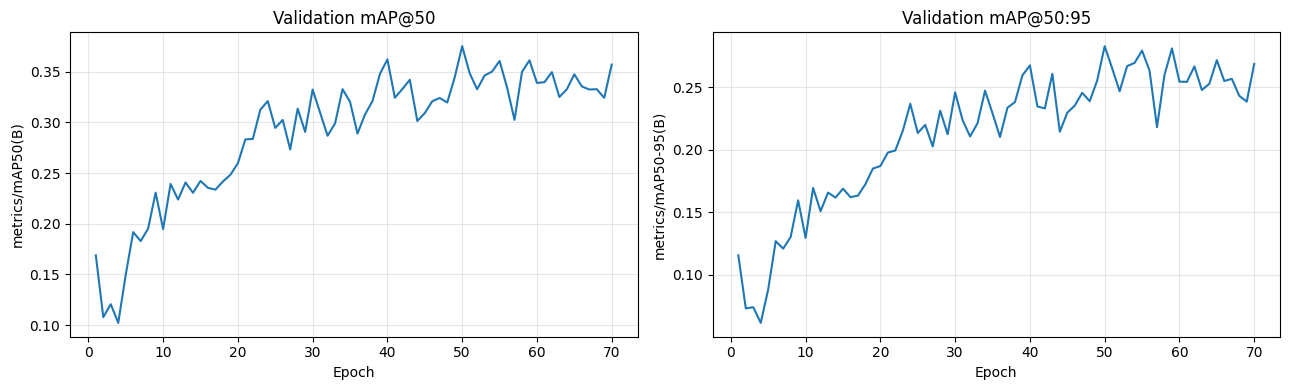

In [11]:
import matplotlib.pyplot as plt

if RUN_DIR is not None and (RUN_DIR / 'results.csv').exists():
    history = pd.read_csv(RUN_DIR / 'results.csv')
    history.columns = history.columns.str.strip()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for axis, metric, title in zip(
        axes,
        ['metrics/mAP50(B)', 'metrics/mAP50-95(B)'],
        ['Validation mAP@50', 'Validation mAP@50:95']
    ):
        axis.plot(history['epoch'], history[metric])
        axis.set(xlabel='Epoch', ylabel=metric, title=title)
        axis.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print('Training CSV was not found, but evaluation and predictions still work.')